In [2]:
import uproot
import numpy as np
from collections import Counter

FILE = r"C:\Users\USER\Downloads\mftclusters_1.root"

file = uproot.open(FILE)
print("objects in this file:", file.keys(cycle=False))

objects in this file: ['o2sim']


## 1. What is inside?

- A ROOT file holds **trees**.
- A tree holds **branches**.
- A branch holds **leaves**, and the leaves hold the numbers.
- The tree here is called `o2sim`.

In [5]:
tree = file["o2sim"]

print("entries (rows):", tree.num_entries)
print()

for name, branch in tree.items():
    print(f"{name:<45} {branch.typename}")

entries (rows): 1

MFTClusterComp                                vector<o2::itsmft::CompClusterExt>
MFTClusterComp/MFTClusterComp.mData           uint32_t[]
MFTClusterComp/MFTClusterComp.mChipID         uint16_t[]
MFTClusterPatt                                std::vector<uint8_t>
MFTClustersROF                                vector<o2::itsmft::ROFRecord>
MFTClustersROF/MFTClustersROF.mBCData.bc      uint16_t[]
MFTClustersROF/MFTClustersROF.mBCData.orbit   uint32_t[]
MFTClustersROF/MFTClustersROF.mROFEntry.mFirstEntry int32_t[]
MFTClustersROF/MFTClustersROF.mROFEntry.mEntries int32_t[]
MFTClustersROF/MFTClustersROF.mROFrame        uint32_t[]
MFTClustersROF/MFTClustersROF.mBits           uint32_t[]
MFTClusterMCTruth                             o2::dataformats::MCTruthContainer<o2::MCCompLabel>
MFTClustersMC2ROF                             vector<o2::itsmft::MC2ROFRecord>
MFTClustersMC2ROF/MFTClustersMC2ROF.eventRecordID int32_t[]
MFTClustersMC2ROF/MFTClustersMC2ROF.rofRecordID int32_t[]


## 2. Read the clusters


In [12]:
chipID = np.asarray(tree["MFTClusterComp.mChipID"].array()[0])
mData  = np.asarray(tree["MFTClusterComp.mData"].array()[0])

print("number of clusters:", len(chipID))
print("first 10 chipIDs  :", chipID[:10])
print("first 10 mData    :", mData[:10])
print()
print("chipID range:", chipID.min(), "->", chipID.max())
print("different chips hit:", len(np.unique(chipID)), "out of 936")

number of clusters: 15020
first 10 chipIDs  : [ 3  4 10 11 15 19 21 21 27 28]
first 10 mData    : [3653840  449771 3265369 4159943 1722176  363731 2856285 1951833  514248
 5494693]

chipID range: 0 -> 935
different chips hit: 901 out of 936


## 3. Decode mData into row and column


In [13]:
row       = mData & 0x1FF
col       = (mData >> 9) & 0x3FF
patternID = (mData >> 19)

print(f"{'#':>4}  {'chipID':>7}  {'row':>5}  {'col':>5}  {'pattID':>7}")
for j in range(10):
    print(f"{j:>4}  {chipID[j]:>7}  {row[j]:>5}  {col[j]:>5}  {patternID[j]:>7}")

print()
print("row  max:", row.max(), " (sensor has 512 rows)")
print("col  max:", col.max(), " (sensor has 1024 columns)")

   #   chipID    row    col   pattID
   0        3    208    992        6
   1        4    235    878        0
   2       10    345    233        6
   3       11    455    956        7
   4       15    320    291        3
   5       19    211    710        0
   6       21    349    458        5
   7       21     89    740        3
   8       27    200   1004        0
   9       28    421    491       10

row  max: 511  (sensor has 512 rows)
col  max: 1023  (sensor has 1024 columns)


## 4. The ROFs - time slices

A **ROF** (ReadOut Frame) is one time window of the detector.

- `bc` = bunch crossing number inside one LHC orbit
- `orbit` = which turn around the LHC ring
- `mFirstEntry` / `mEntries` = which clusters belong to this ROF

In [14]:
bc    = np.asarray(tree["MFTClustersROF.mBCData.bc"].array()[0])
orbit = np.asarray(tree["MFTClustersROF.mBCData.orbit"].array()[0])
first = np.asarray(tree["MFTClustersROF.mROFEntry.mFirstEntry"].array()[0])
nclus = np.asarray(tree["MFTClustersROF.mROFEntry.mEntries"].array()[0])

print("number of ROFs:", len(bc))
print()
print(f"{'ROF':>4}  {'orbit':>12}  {'bc':>6}  {'firstClus':>10}  {'nClus':>6}")
for r in range(8):
    print(f"{r:>4}  {orbit[r]:>12}  {bc[r]:>6}  {first[r]:>10}  {nclus[r]:>6}")

print()
print("bc spacing:", bc[1] - bc[0], "bunch crossings between ROFs")

number of ROFs: 192

 ROF         orbit      bc   firstClus   nClus
   0     470804416       0           0     176
   1     470804416     594         176       5
   2     470804416    1188         181       7
   3     470804416    1782         188     106
   4     470804416    2376         294       7
   5     470804416    2970         301       3
   6     470804417       0         304       2
   7     470804417     594         306     318

bc spacing: 594 bunch crossings between ROFs


## 5. Which clusters come from the SAME particle?

The branch `MFTClusterMCTruth` holds an **MCCompLabel** for every cluster:

- `sourceID` - which generator
- `eventID` - which collision
- `trackID` - which particle in that collision

Two clusters with the **same three numbers** were made by the same particle.


In [15]:
raw = np.asarray(tree["MFTClusterMCTruth"].debug_array(0), dtype=np.uint8)

offset = None
for off in range(256):
    if off + 8 > len(raw):
        break
    nH, nT = np.frombuffer(raw[off:off+8].tobytes(), dtype="<u4")
    nH, nT = int(nH), int(nT)
    if nH and nT and off + 8 + 4*nH + 8*nT == len(raw):
        offset = off
        break

print("offset:", offset, " clusters:", nH, " labels:", nT)

start  = offset + 8
idx    = np.frombuffer(raw[start:start+4*nH].tobytes(), dtype="<u4").astype(np.int64)
labels = np.frombuffer(raw[start+4*nH:].tobytes(), dtype="<u8")

trackID  = (labels & ((1 << 31) - 1)).astype(np.int64)
eventID  = ((labels >> 31) & ((1 << 19) - 1)).astype(np.int64)
sourceID = ((labels >> 50) & 0xFF).astype(np.int64)

first_lab = idx                       
is_noise  = sourceID[first_lab] == 255
is_real   = ~is_noise

print("clusters from a particle:", int(is_real.sum()))
print("clusters that are noise :", int(is_noise.sum()))

offset: 44  clusters: 15020  labels: 15378
clusters from a particle: 14116
clusters that are noise : 904


In [16]:
key = (sourceID[first_lab] << 50) | (eventID[first_lab] << 31) | trackID[first_lab]

key_real  = key[is_real]
chip_real = chipID[is_real]

counts = Counter(key_real.tolist())
print("different particles (tracks):", len(counts))

hist = Counter(counts.values())
print("\nclusters per track:")
for n in sorted(hist):
    print(f"  {n:>3} cluster(s): {hist[n]:>5} tracks  {'#' * (hist[n]//10)}")

total = sum(n*k for n, k in hist.items())
print(f"\nmean clusters per track: {total/len(counts):.2f}")
print("the MFT has 5 disks x 2 sensor planes = 10 layers,")
print("so one particle can leave at most 10 clusters")

different particles (tracks): 2842

clusters per track:
    1 cluster(s):   542 tracks  ######################################################
    2 cluster(s):   289 tracks  ############################
    3 cluster(s):   230 tracks  #######################
    4 cluster(s):   199 tracks  ###################
    5 cluster(s):   180 tracks  ##################
    6 cluster(s):   261 tracks  ##########################
    7 cluster(s):   413 tracks  #########################################
    8 cluster(s):   452 tracks  #############################################
    9 cluster(s):   227 tracks  ######################
   10 cluster(s):    47 tracks  ####
   12 cluster(s):     2 tracks  

mean clusters per track: 4.97
the MFT has 5 disks x 2 sensor planes = 10 layers,
so one particle can leave at most 10 clusters


In [17]:
print(f"{'trackID':>9} {'evID':>6} {'nClus':>6}   chipIDs")

shown = 0
for k, c in counts.items():
    if c < 2:
        continue
    mask = key_real == k
    chips = sorted(chip_real[mask].tolist())
    print(f"{k & ((1<<31)-1):>9} {(k >> 31) & ((1<<19)-1):>6} {c:>6}   {chips}")
    shown += 1
    if shown >= 10:
        break

  trackID   evID  nClus   chipIDs
      175      5      9   [3, 11, 69, 77, 135, 224, 242, 342, 354]
      308      5      2   [4, 70]
      309      5      7   [10, 76, 134, 138, 242, 342, 354]
      510      5      9   [15, 42, 81, 164, 182, 249, 289, 361, 397]
      333      5      7   [19, 85, 109, 187, 199, 254, 450]
      507      5      8   [21, 48, 87, 146, 167, 260, 301, 401]
      352      5      8   [21, 87, 111, 203, 256, 300, 364, 454]
      132      5      8   [27, 93, 120, 152, 173, 268, 312, 412]
      506      5      7   [28, 55, 94, 121, 174, 274, 382]
      180      5      8   [34, 58, 100, 195, 212, 282, 445, 465]


## 6. Run the full programs

In [ ]:
%run read_everything.py

In [ ]:
%run find_tracks.py

---
# 7. Pseudo efficiency of the MFT

A different file, and a different question.

Everything above used **clusters**. From here we use **reconstructed tracks**,
from the p-O AO2D file.

**The question:** how often does each MFT layer detect a particle that
passed through it?

**The problem:** in data nobody tells us how many particles passed.

**The trick (tag and probe):** let the track be its own witness. If a track
has clusters *before* layer L and *after* layer L, the particle must have
crossed L - it cannot jump around a layer. So we may ask whether L recorded it.

$$\text{efficiency}(L) = \frac{\text{tracks with a cluster on } L}{\text{tracks proven to have crossed } L}$$

Layers 0 and 9 are the edges: nothing sits before layer 0 or after layer 9,
so they cannot be bracketed. We report them as not measurable.


## 7a. Open the track table


In [5]:
import uproot
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

AO2D = r"C:\Users\USER\Downloads\AO2D_MC_pO_generalPurpose_anchoredPass2_merged.root"

# z of each sensor plane, in cm, from the MFT geometry
Z_LAYER = [-45.3, -46.7, -48.6, -50.0, -52.3,
           -53.7, -67.7, -69.2, -76.1, -77.5]

mft_file = uproot.open(AO2D)
frames = [k for k in mft_file.keys(recursive=False, cycle=False) if k.startswith("DF_")]
mft_df = mft_file[frames[0]]
tname = [k for k in mft_df.keys(recursive=False, cycle=False) if k.startswith("O2mfttrack")][0]
mft_tree = mft_df[tname]

print("data frames :", len(frames))
print("track table :", tname)
print("MFT tracks  :", f"{mft_tree.num_entries:,}")
print()
for nm, br in mft_tree.items():
    print(f"   {nm:<34} {br.typename}")

data frames : 1
track table : O2mfttrack_001
MFT tracks  : 171,278

   fIndexCollisions                   int32_t
   fX                                 float
   fY                                 float
   fZ                                 float
   fPhi                               float
   fTgl                               float
   fSigned1Pt                         float
   fMFTClusterSizesAndTrackFlags      uint64_t
   fChi2                              float
   fTrackTime                         float
   fTrackTimeRes                      float


## b. Decode the cluster sizes


In [6]:
mft_arr = mft_tree.arrays(["fX", "fY", "fZ", "fPhi", "fTgl",
                           "fMFTClusterSizesAndTrackFlags"], library="np")

flags = mft_arr["fMFTClusterSizesAndTrackFlags"].astype(np.uint64)
n_trk = len(flags)

mft_sizes = np.zeros((n_trk, 10), dtype=np.int64)
for lay in range(10):
    mft_sizes[:, lay] = (flags >> np.uint64(lay * 6)) & np.uint64(0x3F)

mft_has = mft_sizes > 0            # did this layer record the track?
mft_nclus = mft_has.sum(axis=1)
is_ca = ((flags >> np.uint64(60)) & np.uint64(1)).astype(bool)

print(f"clusters per track: min {mft_nclus.min()}, max {mft_nclus.max()}, "
      f"mean {mft_nclus.mean():.2f}")
print(f"Cellular Automaton: {is_ca.sum():,}    Linear Track Finder: {(~is_ca).sum():,}")
print()
for lay in range(10):
    print(f"  layer {lay}: {mft_has[:,lay].sum():>7,} tracks have a cluster here")

clusters per track: min 5, max 10, mean 7.30
Cellular Automaton: 7,869    Linear Track Finder: 163,409

  layer 0: 126,090 tracks have a cluster here
  layer 1: 119,364 tracks have a cluster here
  layer 2: 109,684 tracks have a cluster here
  layer 3: 125,977 tracks have a cluster here
  layer 4: 136,110 tracks have a cluster here
  layer 5: 129,908 tracks have a cluster here
  layer 6: 126,118 tracks have a cluster here
  layer 7: 129,963 tracks have a cluster here
  layer 8: 124,524 tracks have a cluster here
  layer 9: 123,377 tracks have a cluster here


## 8c. Tag and probe



In [7]:
eff, err, lays = [], [], []

print(f"{'layer':>6} {'probes':>10} {'found':>10} {'efficiency':>14}")
print("-" * 44)

for L in range(10):
    before = mft_has[:, :L].any(axis=1)   if L > 0 else np.zeros(n_trk, bool)
    after  = mft_has[:, L+1:].any(axis=1) if L < 9 else np.zeros(n_trk, bool)
    probe  = before & after               # proven to have crossed layer L

    if probe.sum() == 0:
        print(f"{L:>6} {'-':>10} {'-':>10} {'not measurable':>14}")
        continue

    found = probe & mft_has[:, L]
    e = found.sum() / probe.sum()
    u = np.sqrt(e * (1 - e) / probe.sum())      # binomial error

    print(f"{L:>6} {probe.sum():>10,} {found.sum():>10,} {100*e:>12.2f} %")
    lays.append(L); eff.append(e); err.append(u)

 layer     probes      found     efficiency
--------------------------------------------
     0          -          - not measurable
     1    126,090     84,448        66.97 %
     2    161,006    104,509        64.91 %
     3    166,181    120,880        72.74 %
     4    171,278    136,110        79.47 %
     5    171,278    129,908        75.85 %
     6    166,845    121,685        72.93 %
     7    158,065    121,183        76.67 %
     8    123,377     89,836        72.81 %
     9          -          - not measurable


In [8]:
def one_sided(L, neighbours):
    """probe = tracks with a cluster on ALL these layers (same side)"""
    p = np.ones(n_trk, bool)
    for m in neighbours:
        p &= mft_has[:, m]
    return p


print("step 1 -- test the method where we already know the answer\n")
print(f"{'layer':>6} {'neighbours':>14} {'one-sided':>11} {'two-sided':>11} {'ratio':>8}")
print("-" * 56)

ratios = {"outer": [], "inner": []}

checks = [(8, [5, 6, 7], "outer"), (7, [4, 5, 6], "outer"), (6, [3, 4, 5], "outer"),
          (1, [2, 3, 4], "inner"), (2, [3, 4, 5], "inner"), (3, [4, 5, 6], "inner")]

for L, neigh, side in checks:
    p1 = one_sided(L, neigh)
    e1 = (p1 & mft_has[:, L]).sum() / p1.sum()
    p2 = mft_has[:, :L].any(axis=1) & mft_has[:, L+1:].any(axis=1)
    e2 = (p2 & mft_has[:, L]).sum() / p2.sum()
    print(f"{L:>6} {str(neigh):>14} {100*e1:>10.2f}% {100*e2:>10.2f}% {e2/e1:>8.4f}")
    ratios[side].append(e2 / e1)

k_out, k_in = np.mean(ratios["outer"]), np.mean(ratios["inner"])
s_out, s_in = np.std(ratios["outer"]),  np.std(ratios["inner"])

print(f"\ncorrection   outer {k_out:.4f} +/- {s_out:.4f}    inner {k_in:.4f} +/- {s_in:.4f}")

print("\nstep 2 -- how much does the choice of probe matter?\n")
print(f"{'layer':>6} {'neighbours':>22} {'probes':>10} {'raw eff':>10}")
print("-" * 52)

variants = {
    0: [[1], [1, 2], [1, 2, 3], [1, 2, 3, 4], [1, 2, 3, 4, 5]],
    9: [[8], [7, 8], [6, 7, 8], [5, 6, 7, 8], [4, 5, 6, 7, 8]],
}
spread = {}

for L in (0, 9):
    vals = []
    for neigh in variants[L]:
        p = one_sided(L, neigh)
        e = (p & mft_has[:, L]).sum() / p.sum()
        vals.append(e)
        print(f"{L:>6} {str(neigh):>22} {p.sum():>10,} {100*e:>9.2f} %")
    spread[L] = float(np.std(vals))
    print(f"{'':>6} {'spread (std dev)':>22} {'':>10} {100*spread[L]:>9.2f} %\n")

print("step 3 -- measure layers 0 and 9\n")

edge_l, edge_e, edge_stat, edge_sys = [], [], [], []

for L, neigh, k, s in [(0, [1, 2, 3], k_in, s_in),
                       (9, [6, 7, 8], k_out, s_out)]:

    p = one_sided(L, neigh)
    raw = (p & mft_has[:, L]).sum() / p.sum()

    e     = raw * k
    stat  = np.sqrt(raw * (1 - raw) / p.sum()) * k
    s_cal = raw * s                 # from the calibration checks
    s_met = spread[L] * k           # from the choice of probe

    syst = np.sqrt(s_cal**2 + s_met**2)     # independent, so in quadrature

    print(f"  layer {L}: probes {p.sum():>7,}   raw {100*raw:>6.2f} %"
          f"   -> corrected {100*e:>6.2f} %")
    print(f"           +/- {100*stat:.2f} (stat)  +/- {100*s_cal:.2f} (calibration)"
          f"  +/- {100*s_met:.2f} (probe choice)  = +/- {100*syst:.2f} (total syst)")

    edge_l.append(L); edge_e.append(e)
    edge_stat.append(stat); edge_sys.append(syst)

print("\nlayer 9 barely moves with the probe choice, so it is solid.")
print("layer 0 moves a lot, so its uncertainty is much larger.")

step 1 -- test the method where we already know the answer

 layer     neighbours   one-sided   two-sided    ratio
--------------------------------------------------------
     8      [5, 6, 7]      72.80%      72.81%   1.0002
     7      [4, 5, 6]      71.61%      76.67%   1.0706
     6      [3, 4, 5]      75.72%      72.93%   0.9632
     1      [2, 3, 4]      67.60%      66.97%   0.9908
     2      [3, 4, 5]      59.30%      64.91%   1.0946
     3      [4, 5, 6]      73.94%      72.74%   0.9838

correction   outer 1.0113 +/- 0.0445    inner 1.0231 +/- 0.0507

step 2 -- how much does the choice of probe matter?

 layer             neighbours     probes    raw eff
----------------------------------------------------
     0                    [1]    119,364     70.75 %
     0                 [1, 2]     70,678     76.29 %
     0              [1, 2, 3]     50,376     77.78 %
     0           [1, 2, 3, 4]     38,455     72.89 %
     0        [1, 2, 3, 4, 5]     27,063     81.40 %
         

## 8d. Efficiency per layer


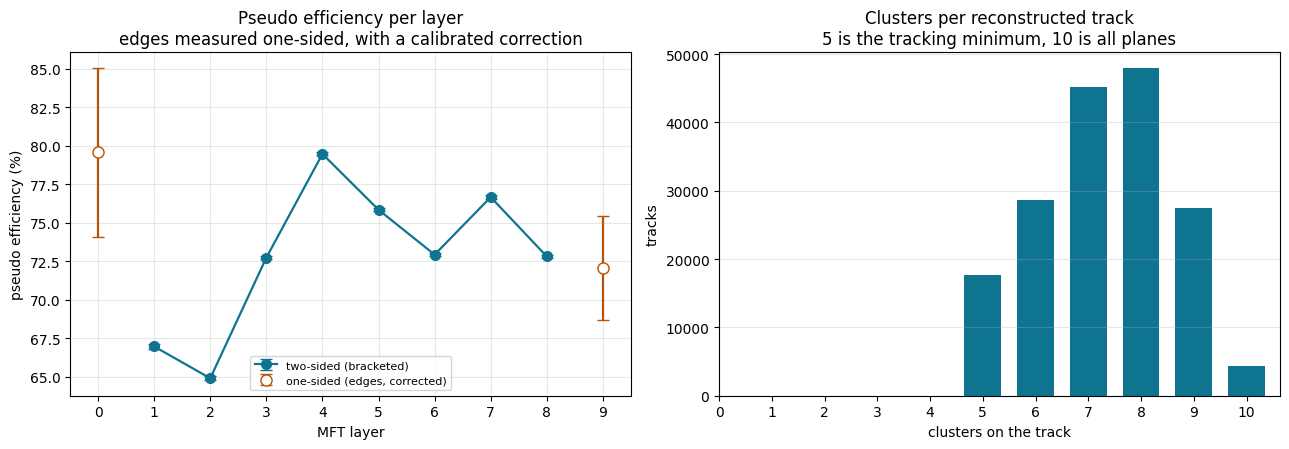

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

ax[0].errorbar(lays, 100*np.array(eff), yerr=100*np.array(err),
               fmt="o-", color="#0e7490", markersize=7, capsize=4, lw=1.6,
               label="two-sided (bracketed)")

tot_err = np.sqrt(np.array(edge_stat)**2 + np.array(edge_sys)**2)
ax[0].errorbar(edge_l, 100*np.array(edge_e), yerr=100*tot_err,
               fmt="o", mfc="white", color="#b45309", markersize=8,
               capsize=4, lw=1.6, label="one-sided (edges, corrected)")

ax[0].legend(fontsize=8, loc="lower center")
ax[0].set_xlabel("MFT layer")
ax[0].set_ylabel("pseudo efficiency (%)")
ax[0].set_title("Pseudo efficiency per layer\nedges measured one-sided, with a calibrated correction")
ax[0].set_xticks(range(10)); ax[0].set_xlim(-0.5, 9.5); ax[0].grid(alpha=0.3)

vals, cnts = np.unique(mft_nclus, return_counts=True)
ax[1].bar(vals, cnts, color="#0e7490", width=0.7)
ax[1].set_xlabel("clusters on the track")
ax[1].set_ylabel("tracks")
ax[1].set_title("Clusters per reconstructed track\n5 is the tracking minimum, 10 is all planes")
ax[1].set_xticks(range(0, 11)); ax[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

## 8e. Where does the MFT lose particles?



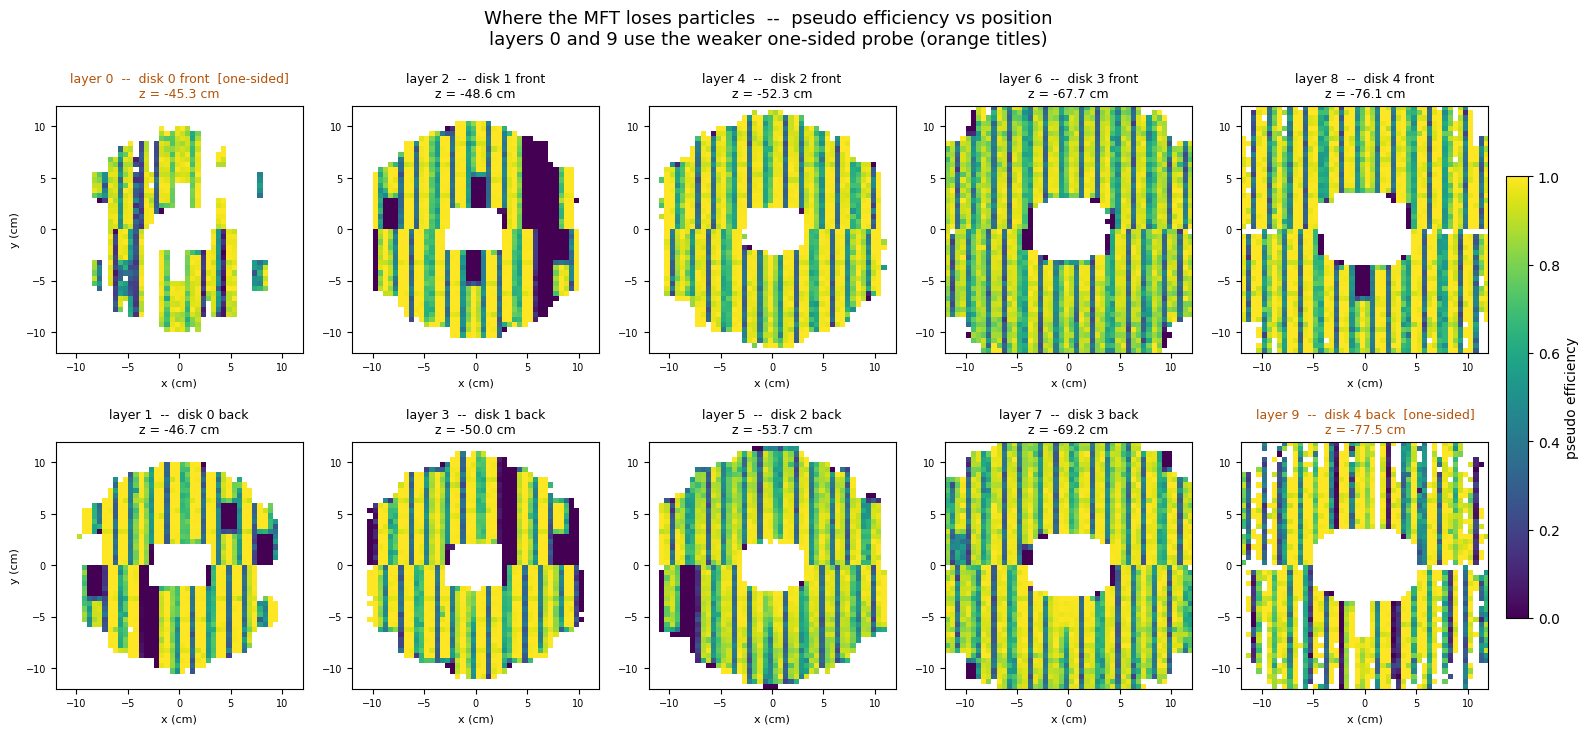

In [10]:
def extrapolate(x, y, z, phi, tgl, z_target):
    """follow a straight line from the track's reference point to z_target"""
    dz = z_target - z
    return x + np.cos(phi)/tgl*dz, y + np.sin(phi)/tgl*dz


def probe_for(L):
    """
    Which tracks are proven to have crossed layer L?

    Layers 1-8: clusters on both sides (the strong test).
    Layers 0, 9: no layer on one side, so fall back to the
    one-sided probe - clusters on the three neighbours we do
    have. Weaker, so those two panels are marked.
    """
    if L == 0:
        return one_sided(0, [1, 2, 3]), True
    if L == 9:
        return one_sided(9, [6, 7, 8]), True
    return (mft_has[:, :L].any(axis=1) & mft_has[:, L+1:].any(axis=1)), False


bins = np.linspace(-12, 12, 49)      

fig2, axes = plt.subplots(2, 5, figsize=(19, 8))

for L in range(10):
    ax2 = axes[L % 2][L // 2]      

    probe, weak = probe_for(L)

    xe, ye = extrapolate(mft_arr["fX"][probe], mft_arr["fY"][probe],
                         mft_arr["fZ"][probe], mft_arr["fPhi"][probe],
                         mft_arr["fTgl"][probe], Z_LAYER[L])
    hit = mft_has[probe, L]

    h_all, _, _ = np.histogram2d(xe, ye, bins=[bins, bins])
    h_hit, _, _ = np.histogram2d(xe[hit], ye[hit], bins=[bins, bins])

    with np.errstate(invalid="ignore", divide="ignore"):
        eff_map = np.where(h_all >= 10, h_hit/h_all, np.nan)

    im = ax2.imshow(eff_map.T, origin="lower", cmap="viridis",
                    extent=[bins[0], bins[-1], bins[0], bins[-1]], vmin=0, vmax=1)

    face = "front" if L % 2 == 0 else "back"
    tag  = "  [one-sided]" if weak else ""
    ax2.set_title(f"layer {L}  --  disk {L//2} {face}{tag}\nz = {Z_LAYER[L]} cm",
                  fontsize=9, color="#b45309" if weak else "black")
    ax2.set_xlabel("x (cm)", fontsize=8)
    if L // 2 == 0:
        ax2.set_ylabel("y (cm)", fontsize=8)
    ax2.tick_params(labelsize=7)

cb = fig2.colorbar(im, ax=axes, fraction=0.015, pad=0.012)
cb.set_label("pseudo efficiency")
fig2.suptitle("Where the MFT loses particles  --  pseudo efficiency vs position\n"
              "layers 0 and 9 use the weaker one-sided probe (orange titles)",
              fontsize=13)
plt.show()

## 8f. The same losses, projected two ways




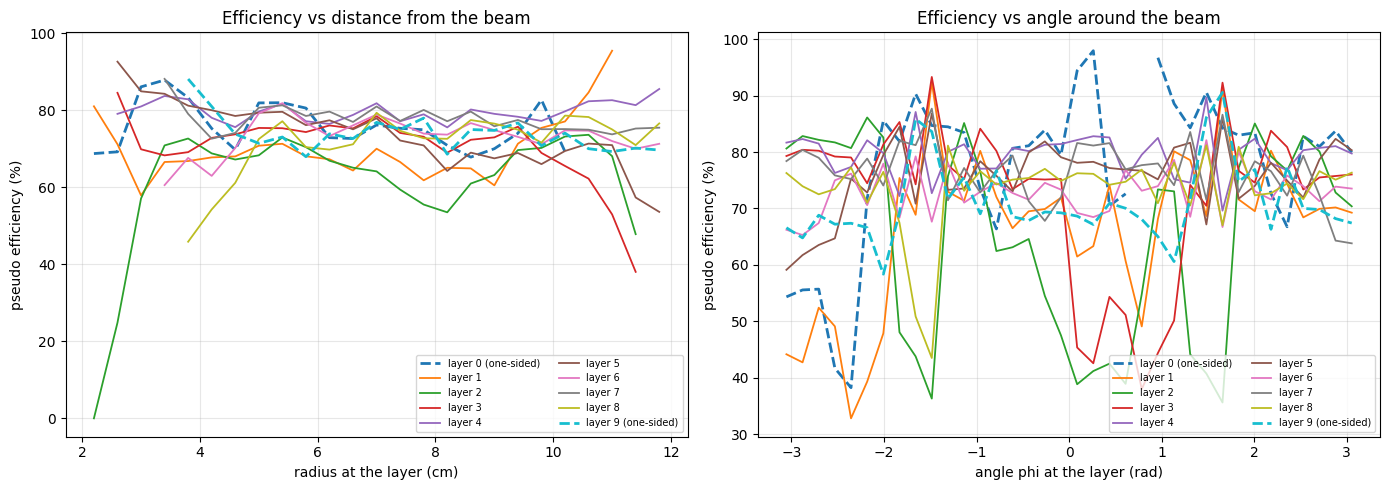

In [11]:
fig3, ax3 = plt.subplots(1, 2, figsize=(14, 5))

r_bins   = np.linspace(2, 12, 26)               
phi_bins = np.linspace(-np.pi, np.pi, 37)       

for L in range(10):                             

    probe, weak = probe_for(L)

    xe, ye = extrapolate(mft_arr["fX"][probe], mft_arr["fY"][probe],
                         mft_arr["fZ"][probe], mft_arr["fPhi"][probe],
                         mft_arr["fTgl"][probe], Z_LAYER[L])
    hit = mft_has[probe, L]

    rr = np.sqrt(xe*xe + ye*ye)                 
    pp = np.arctan2(ye, xe)                     

    style = dict(lw=2.0, ls="--") if weak else dict(lw=1.3, ls="-")
    label = f"layer {L}" + (" (one-sided)" if weak else "")

    for vals, bb, axx in ((rr, r_bins, ax3[0]), (pp, phi_bins, ax3[1])):
        n_all, _ = np.histogram(vals, bins=bb)
        n_hit, _ = np.histogram(vals[hit], bins=bb)
        with np.errstate(invalid="ignore", divide="ignore"):
            e = np.where(n_all >= 20, n_hit/n_all, np.nan)   
        centres = 0.5 * (bb[1:] + bb[:-1])
        axx.plot(centres, 100*e, label=label, **style)

ax3[0].set_xlabel("radius at the layer (cm)")
ax3[0].set_ylabel("pseudo efficiency (%)")
ax3[0].set_title("Efficiency vs distance from the beam")
ax3[0].grid(alpha=0.3)
ax3[0].legend(fontsize=7, ncol=2)

ax3[1].set_xlabel("angle phi at the layer (rad)")
ax3[1].set_ylabel("pseudo efficiency (%)")
ax3[1].set_title("Efficiency vs angle around the beam")
ax3[1].grid(alpha=0.3)
ax3[1].legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.show()

In [4]:
%matplotlib inline

In [7]:
import uproot, re

f = uproot.open(FILE)
k = f.key("metaData")

try:
    raw = k.data_uncompressed
except AttributeError:
    import uproot.compression
    chunk = f.file.source.chunk(
        k.data_cursor.index,
        k.data_cursor.index + k.data_compressed_bytes)
    raw = uproot.compression.decompress(
        chunk, k.data_cursor, {},
        k.data_compressed_bytes, k.data_uncompressed_bytes).raw_data

for s in re.findall(rb"[ -~]{4,}", raw):
    print(s.decode())

TObjString
O2Version@
1.2.0@
LPMProductionTag@
LHC25h2@
ROOTVersion@
6.32.06@
RecoPassName@
CreatedBy@
aliprod@
Run@
AnchorPassName@
apass2@
DataType@
AnchorProduction@
LHC25ad


In [8]:
import re
import uproot

FILE = r"C:\Users\USER\Downloads\AO2D_MC_pO_generalPurpose_anchoredPass2_merged.root"

f = uproot.open(FILE)
k = f.key("metaData")

try:
    raw = k.data_uncompressed
except AttributeError:
    import uproot.compression
    chunk = f.file.source.chunk(
        k.data_cursor.index,
        k.data_cursor.index + k.data_compressed_bytes)
    raw = uproot.compression.decompress(
        chunk, k.data_cursor, {},
        k.data_compressed_bytes, k.data_uncompressed_bytes).raw_data

items = [s.decode().rstrip("@") for s in re.findall(rb"[ -~]{2,}", raw)]
items = [s for s in items if s and s != "TObjString"]

print("--- everything found, in order ---")
for i, s in enumerate(items):
    print(f"{i:>3}  {s}")

--- everything found, in order ---
  0  O2Version
  1  U
  2  1.2.0
  3  U
  4  LPMProductionTag
  5  U
  6  LHC25h2
  7  U
  8  ROOTVersion
  9  U
 10  6.32.06
 11  U
 12  RecoPassName
 13  U
 14  U
 15  CreatedBy
 16  U
 17  aliprod
 18  U
 19  Run
 20  U
 21  3
 22  U
 23  AnchorPassName
 24  U
 25  apass2
 26  U
 27  DataType
 28  U
 29  MC
 30  U
 31  AnchorProduction
 32  U
 33  LHC25ad
